In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, glob, pickle, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
warnings.filterwarnings("ignore")

ROOT = "/content/drive/MyDrive/dtn_project"
RES_B = f"{ROOT}/results_b"
CACHE = f"{RES_B}/exp2_cache"
DATASETS = ["5g", "4g", "operator"]
W = 30
EVENT_Q, EVENT_GAP, TOL = 0.97, 50, 100
STRATS = ["kswin", "adwin", "fixed_kswin"]
U = {}
for f in sorted(glob.glob(f"{CACHE}/*.pkl")):
    ds, kind, tr = os.path.basename(f)[:-4].split("__", 2)
    U[(ds, kind, tr)] = pickle.load(open(f, "rb"))
print(len(U), "replays loaded")
for ds in DATASETS:
    print(ds, "units:", sum(k[0] == ds for k in U), "| test steps per trace (median):",
          int(np.median([len(v["y"]) for k, v in U.items() if k[0] == ds])))

Mounted at /content/drive
120 replays loaded
5g units: 40 | test steps per trace (median): 379
4g units: 40 | test steps per trace (median): 238
operator units: 40 | test steps per trace (median): 2148


## 2. Do alarms line up with a rise in error? Events caught, late and false alarms
**Rise test:** for every alarm at step j we compare the average error of `none` in the 30 steps before j with the 30 steps before that (ratio above 1 = error was rising). The same ratio is computed at the same number of **random** moments as a control. If alarms really follow error rises, their ratios should be clearly higher than the random ones.

**Events:** see the definitions above. **Caught** = alarm within 100 steps of the event start; **false alarm** = no event started in the 100 steps before it.

In [2]:
def events(err):
    idx = np.where(err > np.quantile(err, EVENT_Q))[0]
    if len(idx) == 0: return []
    return [idx[0]] + [b for a, b in zip(idx[:-1], idx[1:]) if b - a > EVENT_GAP]

def rise(err, j):
    if j < 2 * W: return np.nan
    return err[j - W:j].mean() / max(err[j - 2 * W:j - W].mean(), 1e-12)

rng = np.random.RandomState(0)
rise_rows, det_rows = [], []
for (ds, kind, tr), u in U.items():
    err = np.abs(u["y"].astype("float64") - u["strategies"]["none"]["pred"].astype("float64"))
    ev = events(err)
    for s in STRATS:
        al = list(u["strategies"][s]["alarms"])
        for j in al:
            rise_rows.append(dict(dataset=ds, strategy=s, kind="alarm", ratio=rise(err, j)))
        for j in rng.randint(2 * W, len(err), size=len(al)) if len(al) else []:
            rise_rows.append(dict(dataset=ds, strategy=s, kind="random", ratio=rise(err, j)))
        delays = []
        for e in ev:
            hit = [a for a in al if e <= a <= e + TOL]
            if hit: delays.append(hit[0] - e)
        false = sum(1 for a in al if not any(e <= a <= e + TOL for e in ev))
        det_rows.append(dict(dataset=ds, strategy=s, events=len(ev), caught=len(delays), alarms=len(al),
                             false_alarms=false, delays=delays))
R = pd.DataFrame(rise_rows).dropna()
rows = []
for (ds, s), g in R.groupby(["dataset", "strategy"]):
    a, r = g[g.kind == "alarm"].ratio.values, g[g.kind == "random"].ratio.values
    p = stats.mannwhitneyu(a, r, alternative="greater").pvalue if len(a) > 5 and len(r) > 5 else np.nan
    rows.append(dict(dataset=ds, strategy=s, alarms=len(a), median_ratio_alarm=np.median(a) if len(a) else np.nan,
                     median_ratio_random=np.median(r) if len(r) else np.nan,
                     share_rising_alarm=(a > 1).mean() if len(a) else np.nan,
                     share_rising_random=(r > 1).mean() if len(r) else np.nan, p_alarm_higher=p))
RT = pd.DataFrame(rows)
D = pd.DataFrame(det_rows).groupby(["dataset", "strategy"]).agg(events=("events", "sum"), caught=("caught", "sum"),
        alarms=("alarms", "sum"), false_alarms=("false_alarms", "sum"),
        delays=("delays", lambda x: [d for l in x for d in l])).reset_index()
D["catch_rate"] = D.caught / D.events
D["median_delay_steps"] = D.delays.apply(lambda l: np.median(l) if len(l) else np.nan)
D["false_alarm_share"] = D.false_alarms / D.alarms.replace(0, np.nan)
D = D.drop(columns="delays")
RT.to_csv(f"{RES_B}/error_alarm_rise.csv", index=False); D.to_csv(f"{RES_B}/error_alarm_detection.csv", index=False)
pd.set_option("display.width", 220)
print("RISE TEST (ratio of error just before the alarm to the error before that; random = control)")
print(RT.round(3).to_string(index=False))
print("\nEVENTS CAUGHT AND FALSE ALARMS (all replays of both models)")
print(D.round(3).to_string(index=False))

RISE TEST (ratio of error just before the alarm to the error before that; random = control)
 dataset    strategy  alarms  median_ratio_alarm  median_ratio_random  share_rising_alarm  share_rising_random  p_alarm_higher
      4g       adwin       2               1.868                1.030               1.000                0.500             NaN
      4g fixed_kswin      56               0.986                1.000               0.411                0.500           0.494
      4g       kswin      56               1.280                1.000               0.571                0.536           0.206
      5g fixed_kswin      80               1.002                0.880               0.512                0.400           0.022
      5g       kswin      80               0.668                0.972               0.400                0.438           0.881
operator fixed_kswin     514               1.047                1.028               0.529                0.523           0.093
operator       kswi

## 3. Plot: catch rate and false alarms
For each dataset and strategy: the share of error events caught within 100 steps, and the share of alarms that were false. `fixed_kswin` is the periodic control.


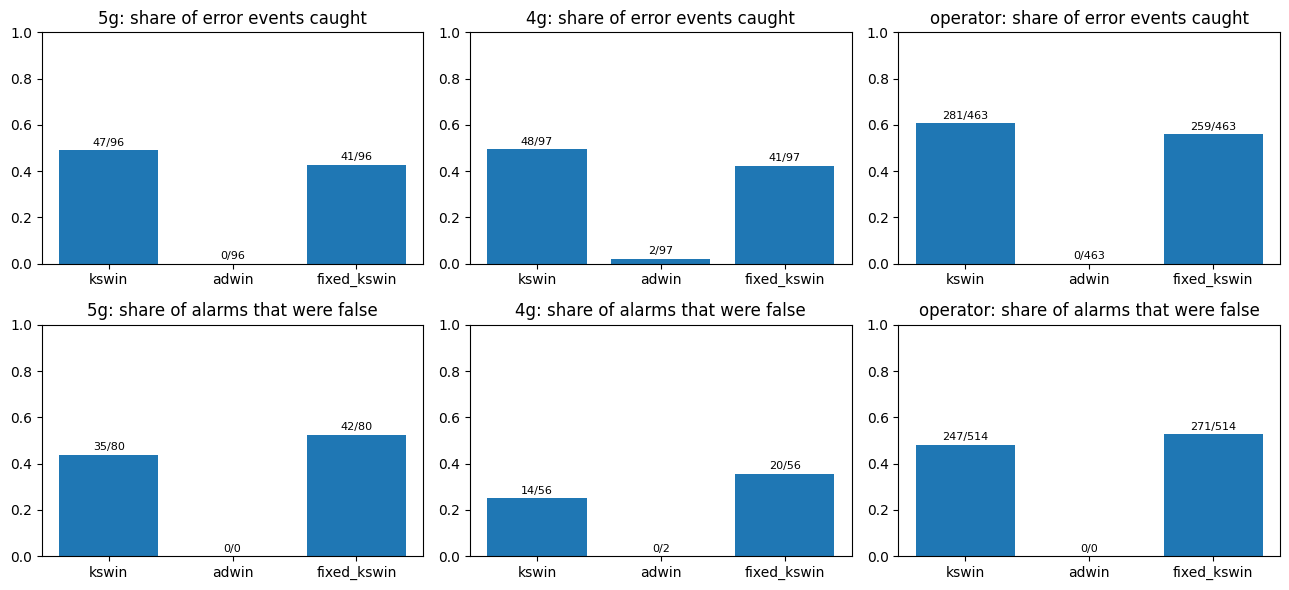

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for j, ds in enumerate(DATASETS):
    d = D[D.dataset == ds].set_index("strategy").reindex(STRATS)
    axes[0, j].bar(d.index, d.catch_rate.fillna(0)); axes[0, j].set_ylim(0, 1)
    axes[0, j].set_title(f"{ds}: share of error events caught");
    axes[1, j].bar(d.index, d.false_alarm_share.fillna(0)); axes[1, j].set_ylim(0, 1)
    axes[1, j].set_title(f"{ds}: share of alarms that were false")
    for i, (s, r) in enumerate(d.iterrows()):
        axes[0, j].text(i, (r.catch_rate if r.catch_rate == r.catch_rate else 0) + .02, f"{int(r.caught)}/{int(r.events)}", ha="center", fontsize=8)
        axes[1, j].text(i, (r.false_alarm_share if r.false_alarm_share == r.false_alarm_share else 0) + .02, f"{int(r.false_alarms)}/{int(r.alarms)}", ha="center", fontsize=8)
plt.tight_layout(); plt.savefig(f"{RES_B}/plot_error_alarms.png", dpi=150, bbox_inches="tight"); plt.show()

## 4. The biggest errors, one by one
Uses the `none` model (Member A's model as saved), pooled over both models and all traces per dataset.
- **Top errors:** the 8 largest single errors per dataset, with the real jump (`y - last value`) and `err_over_jump` (if close to 1, the model essentially missed a jump it could not have known about).
- **Share of error from the top 1% of steps:** how heavy-tailed the errors are.


In [4]:
top, share = [], []
for ds in DATASETS:
    rows = []
    for (d, kind, tr), u in U.items():
        if d != ds: continue
        y, p, l = (u[k].astype("float64") if k != "p" else u["strategies"]["none"]["pred"].astype("float64") for k in ("y", "p", "last"))
        e = np.abs(y - p)
        for i in np.argsort(e)[-5:]:
            rows.append(dict(dataset=ds, model=kind, trace=tr[:34], step=int(i), y=y[i], pred=p[i], last=l[i],
                             jump=y[i] - l[i], abs_err=e[i], err_over_jump=e[i] / abs(y[i] - l[i]) if y[i] != l[i] else np.nan))
    top += sorted(rows, key=lambda r: -r["abs_err"])[:8]
    allsq = np.concatenate([(U[k]["y"].astype("float64") - U[k]["strategies"]["none"]["pred"].astype("float64")) ** 2
                            for k in U if k[0] == ds])
    srt = np.sort(allsq)[::-1]; share.append(dict(dataset=ds, steps=len(srt), top1pct_share_of_squared_error=srt[:max(1, len(srt) // 100)].sum() / srt.sum()))
TOP = pd.DataFrame(top); TOP.to_csv(f"{RES_B}/error_top_errors.csv", index=False)
print(TOP.round(2).to_string(index=False)); print()
SH = pd.DataFrame(share); SH.to_csv(f"{RES_B}/error_heavy_tail.csv", index=False); print(SH.round(3).to_string(index=False))

 dataset  model                              trace  step         y      pred      last       jump   abs_err  err_over_jump
      5g   lstm Download__Driving__B_2020.01.16_09    63 295123.03  48016.97  47344.00  247779.03 247106.06           1.00
      5g bilstm Download__Driving__B_2019.12.16_12    48 257063.00  12377.56   2112.00  254951.00 244685.44           0.96
      5g   lstm Download__Driving__B_2019.12.16_12    48 257063.00  25042.76   2112.00  254951.00 232020.24           0.91
      5g bilstm Download__Driving__B_2020.01.16_09    63 295123.03  72257.72  47344.00  247779.03 222865.31           0.90
      5g bilstm Download__Driving__B_2019.12.16_12    39  99020.00 314171.84 351217.03 -252197.03 215151.84           0.85
      5g   lstm Download__Static__B_2020.02.14_13.   204 244320.00  40701.61  79570.00  164750.00 203618.39           1.24
      5g   lstm Download__Driving__B_2019.12.16_12    37 353379.03 159741.48 270035.00   83344.03 193637.55           2.32
      5g bilstm 

## 5. Which traces are hardest, and where does retraining help?
Traces are grouped by type: 5G by app and driving or static, 4G by transport mode, operator by series type. For each group: the mean RMSE of `none`, of `kswin`, and the change in %.


In [5]:
rows = []
for (ds, kind, tr), u in U.items():
    grp = "__".join(tr.split("__")[:2]) if ds == "5g" else tr.split("__")[0]
    r = lambda s: np.sqrt(np.mean((u["y"].astype("float64") - u["strategies"][s]["pred"].astype("float64")) ** 2))
    rows.append(dict(dataset=ds, group=grp, trace=tr, rmse_none=r("none"), rmse_kswin=r("kswin")))
G = pd.DataFrame(rows).groupby(["dataset", "group"]).agg(replays=("trace", "size"), rmse_none=("rmse_none", "mean"),
                                                        rmse_kswin=("rmse_kswin", "mean")).reset_index()
G["kswin_change_%"] = 100 * (G.rmse_kswin / G.rmse_none - 1)
G.to_csv(f"{RES_B}/error_by_group.csv", index=False)
for ds in DATASETS: print(f"\n== {ds} =="); print(G[G.dataset == ds].drop(columns="dataset").sort_values("rmse_none", ascending=False).round(3).to_string(index=False))


== 5g ==
                group  replays  rmse_none  rmse_kswin  kswin_change_%
     Download__Static        2  42108.114   42087.257          -0.050
    Download__Driving        6  30424.510   30457.143           0.107
      Netflix__Static        8   3407.481    3319.301          -2.588
     Netflix__Driving       12   2860.045    2842.677          -0.607
 Amazon_Prime__Static        6   2696.093    2671.314          -0.919
Amazon_Prime__Driving        6   1524.232    1530.904           0.438

== 4g ==
     group  replays  rmse_none  rmse_kswin  kswin_change_%
pedestrian       12   3720.195    3735.673           0.416
       car       18   3576.845    3582.297           0.152
       bus        4   1651.830    1652.673           0.051
     train        6   1298.951    1292.267          -0.515

== operator ==
     group  replays  rmse_none  rmse_kswin  kswin_change_%
       vpn       12     32.168      31.240          -2.882
  internet        8     10.077       9.015         -10.533
do

## 6. Examples: predictions around the biggest errors
For each dataset: the replay with the largest `none` error (first model). **Top:** real values, the un-retrained prediction and the KSWIN prediction, with a vertical line at every KSWIN retrain. **Bottom:** the error of both (moving average over 20 steps), so you can see whether retraining brings the error down after an alarm.


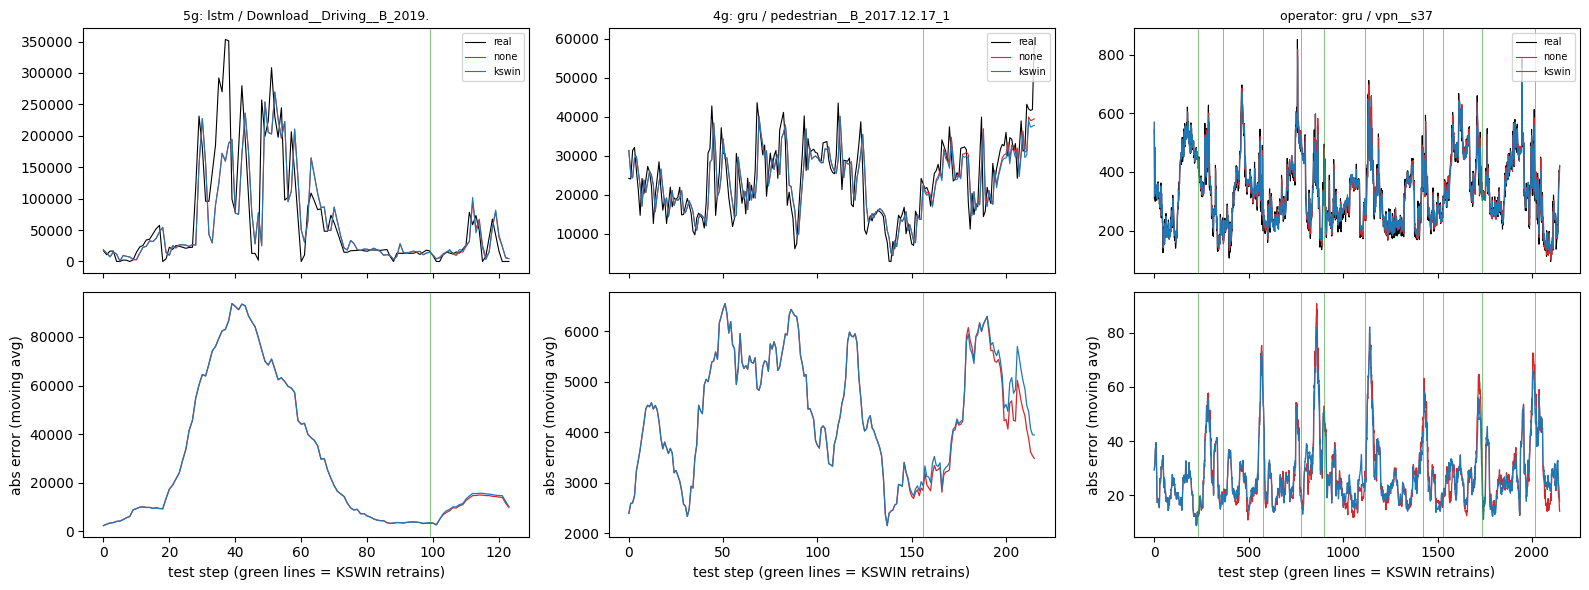

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 6), sharex="col")
for j, ds in enumerate(DATASETS):
    keys = [k for k in U if k[0] == ds]
    k = max(keys, key=lambda k: np.sqrt(np.mean((U[k]["y"].astype("float64") - U[k]["strategies"]["none"]["pred"].astype("float64")) ** 2)))
    u = U[k]; y = u["y"]; pn = u["strategies"]["none"]["pred"]; pk = u["strategies"]["kswin"]["pred"]
    ax = axes[0, j]; ax.plot(y, c="k", lw=.8, label="real"); ax.plot(pn, c="C3", lw=.8, label="none"); ax.plot(pk, c="C0", lw=.8, label="kswin")
    for a in u["strategies"]["kswin"]["alarms"]: ax.axvline(a, c="C2", lw=.6, alpha=.7)
    ax.set_title(f"{ds}: {k[1]} / {k[2][:26]}", fontsize=9); ax.legend(fontsize=7, loc="upper right")
    ma = lambda e: np.convolve(e, np.ones(20) / 20, mode="same")
    ax = axes[1, j]; ax.plot(ma(np.abs(y - pn)), c="C3", lw=.9, label="none"); ax.plot(ma(np.abs(y - pk)), c="C0", lw=.9, label="kswin")
    for a in u["strategies"]["kswin"]["alarms"]: ax.axvline(a, c="C2", lw=.6, alpha=.7)
    ax.set_xlabel("test step (green lines = KSWIN retrains)"); ax.set_ylabel("abs error (moving avg)")
plt.tight_layout(); plt.savefig(f"{RES_B}/plot_error_examples.png", dpi=150, bbox_inches="tight"); plt.show()